# Nghiên cứu và Thực nghiệm Mô hình Phân loại Đánh giá Thời trang Nữ với Support Vector Machine (SVM)

Mục tiêu của notebook này là xây dựng quy trình phân loại cảm xúc (Sentiment Analysis) từ văn bản đánh giá của khách hàng, đồng thời thực nghiệm chuyên sâu qua các bước:
1. Khảo sát & so sánh các kỹ thuật Tokenizer / Vectorizer.
2. Khảo sát & so sánh các SVM Kernel (Linear, RBF, Poly, Sigmoid).
3. Lựa chọn đặc trưng (Feature Selection) với Chi-Square và ANOVA F-Score.
4. Tinh chỉnh siêu tham số (Hyperparameter Tuning) qua GridSearchCV.
5. Học kết hợp (Ensemble Learning) với Bagging, Boosting và Voting.
6. Đóng gói toàn bộ mô hình tối ưu vào khối Config & Scikit-Learn Pipeline.

## 1. Cài đặt môi trường và Thư viện cần thiết

In [1]:
import pandas as pd
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.svm import SVC, LinearSVC
from sklearn.feature_selection import SelectKBest, chi2, f_classif
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, AdaBoostClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score, f1_score, confusion_matrix

sns.set_theme(style="whitegrid")
%matplotlib inline

## 2. Nhập dữ liệu và Tiền xử lý cơ bản

In [2]:
df_raw = pd.read_csv('Womens Clothing E-Commerce Reviews.csv')
df = df_raw[['Review Text', 'Recommended IND']].copy()

# Điền giá trị rỗng và gán nhãn mục tiêu
df['Review Text'] = df['Review Text'].fillna('')
df['Sentiment'] = (df['Recommended IND'] == 1).astype(int)

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['Cleaned_Review'] = df['Review Text'].apply(clean_text)

# Phân chia tập dữ liệu phân tầng (Stratified)
train_data, test_data = train_test_split(
    df, train_size=0.8, random_state=42, stratify=df['Sentiment']
)

X_train_raw = train_data['Cleaned_Review']
y_train = train_data['Sentiment']
X_test_raw = test_data['Cleaned_Review']
y_test = test_data['Sentiment']

print(f"Số lượng mẫu tập huấn luyện: {len(X_train_raw)}")
print(f"Số lượng mẫu tập kiểm tra: {len(X_test_raw)}")
print(f"Tỷ lệ nhãn tích cực (1) trên tập huấn luyện: {y_train.mean():.2%}")

Số lượng mẫu tập huấn luyện: 18788
Số lượng mẫu tập kiểm tra: 4698
Tỷ lệ nhãn tích cực (1) trên tập huấn luyện: 82.24%


## 3. Khảo sát & So sánh các phương pháp Tokenizer & Vectorizer

### Lý thuyết:
Mô hình học máy không thể trực tiếp xử lý văn bản thô. Ta cần đưa văn bản về không gian vector số học:
- **CountVectorizer (Tần số xuất hiện từ)**: Đếm số lần xuất hiện của từ ($TF$). Nhược điểm là các từ phổ biến nhưng ít ý nghĩa có thể chi phối độ lớn của vector.
- **TfidfVectorizer (Word N-grams)**: Nhân tần số từ ($TF$) với nghịch đảo tần số tài liệu ($IDF$). Từ xuất hiện ở hầu hết mọi bài đánh giá sẽ bị giảm trọng số; từ mang tính cảm xúc đặc thù sẽ có trọng số cao hơn. Kết hợp n-gram (1, 2) giúp nắm bắt các cụm từ quan trọng như `not good`, `very pretty`.
- **TF-IDF Char N-grams**: Tách vector theo chuỗi ký tự liền kề (ví dụ: `lov`, `ove`, `ely`). Kỹ thuật này giúp mô hình không bị phụ thuộc vào từ điển từ vựng có sẵn và kháng lỗi chính tả tốt.

In [3]:
tokenizers_pool = {
    "Count_Word_1gram": CountVectorizer(stop_words='english', max_features=4000),
    "TFIDF_Word_1gram": TfidfVectorizer(ngram_range=(1, 1), stop_words='english', max_features=4000),
    "TFIDF_Word_1_2gram": TfidfVectorizer(ngram_range=(1, 2), stop_words='english', max_features=4000),
    "TFIDF_Sublinear_TF": TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, stop_words='english', max_features=4000),
    "TFIDF_Char_3_5gram": TfidfVectorizer(analyzer='char', ngram_range=(3, 5), max_features=4000)
}

tokenizer_results = []

for name, vec in tokenizers_pool.items():
    t0 = dt.datetime.now()
    X_tr = vec.fit_transform(X_train_raw)
    X_te = vec.transform(X_test_raw)
    
    clf = LinearSVC(random_state=42, max_iter=2000)
    clf.fit(X_tr, y_train)
    preds = clf.predict(X_te)
    duration = (dt.datetime.now() - t0).total_seconds()
    
    tokenizer_results.append({
        'Phương pháp Vectorizer': name,
        'Accuracy': accuracy_score(y_test, preds),
        'F1-Score': f1_score(y_test, preds),
        'Thời gian (giây)': round(duration, 2)
    })

df_tok_eval = pd.DataFrame(tokenizer_results)
display(df_tok_eval)

,Phương pháp Vectorizer,Accuracy,F1-Score,Thời gian (giây)
0,Count_Word_1gram,0.869732,0.921739,1.59
1,TFIDF_Word_1gram,0.885909,0.932289,1.27
2,TFIDF_Word_1_2gram,0.882290,0.929867,2.90
3,TFIDF_Sublinear_TF,0.882716,0.930067,2.45
4,TFIDF_Char_3_5gram,0.899745,0.940130,17.53


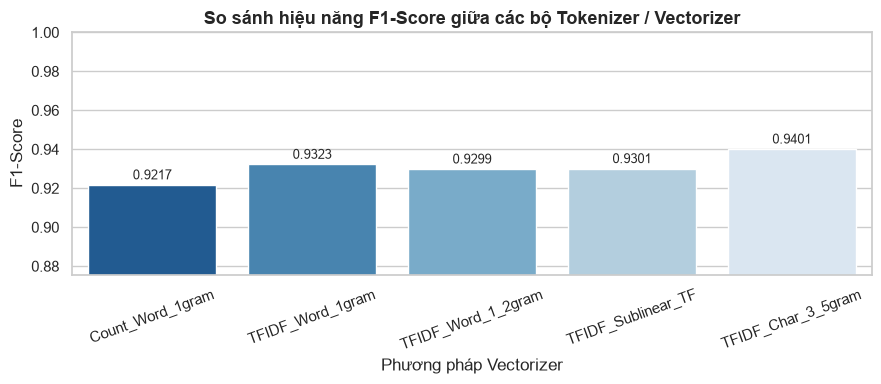

In [4]:
plt.figure(figsize=(9, 4))
ax = sns.barplot(data=df_tok_eval, x='Phương pháp Vectorizer', y='F1-Score', palette='Blues_r')
plt.title("So sánh hiệu năng F1-Score giữa các bộ Tokenizer / Vectorizer", fontsize=13, fontweight='bold')
plt.ylim(df_tok_eval['F1-Score'].min() * 0.95, 1.0)
plt.xticks(rotation=20)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points')
plt.tight_layout()
plt.show()

## 4. Khảo sát & So sánh các SVM Kernel

### Lý thuyết Kernel trong Support Vector Machine:
SVM tìm một siêu phẳng (hyperplane) có khoảng cách biên (margin) xa nhất giữa hai lớp dữ liệu. Tuy nhiên, nhiều bài toán không thể phân tách tuyến tính (linearly separable) trong không gian đặc trưng ban đầu.

**Kernel Trick (Mẹo hạt nhân)**: Là phép toán biến đổi ánh xạ các điểm dữ liệu vào một không gian nhiều chiều hơn, nơi các lớp có thể được phân tách tuyến tính, mà không cần trực tiếp tính toán tọa độ tốn kém trong không gian đó:
- **Linear Kernel / LinearSVC**: Tìm siêu phẳng phẳng trong không gian hiện tại. Trong phân loại văn bản dạng ma trận thưa (hàng nghìn từ), dữ liệu vốn dĩ đã có số chiều rất lớn nên Linear Kernel gần như luôn đạt hiệu quả cao nhất với tốc độ nhanh vượt trội.
- **RBF (Radial Basis Function)**: Ánh xạ vào không gian vô hạn chiều dựa trên khoảng cách Euclidean giữa các điểm. Phù hợp với bài toán biên phi tuyến phức tạp nhưng độ phức tạp tính toán tăng theo bậc mũ $\mathcal{O}(n^2)$ hoặc $\mathcal{O}(n^3)$.
- **Polynomial Kernel**: Ánh xạ tích vô hướng đa thức theo bậc $d$ (xem xét các tổ hợp đặc trưng cùng xuất hiện).
- **Sigmoid Kernel**: Có hành vi tương tự hàm kích hoạt mạng nơ-ron hai lớp.

In [5]:
# Chuẩn bị dữ liệu mẫu chuẩn hóa để so sánh đồng đều các Kernel
shared_vec = TfidfVectorizer(ngram_range=(1, 2), stop_words='english', max_features=3000)
X_train_vec = shared_vec.fit_transform(X_train_raw)
X_test_vec = shared_vec.transform(X_test_raw)

# Trích xuất mẫu nhỏ 4000 bản ghi để đo lường RBF/Poly nhằm tránh treo phiên tính toán
X_sub_train, _, y_sub_train, _ = train_test_split(
    X_train_vec, y_train, train_size=4000, random_state=42, stratify=y_train
)

kernel_candidates = {
    'LinearSVC (liblinear)': LinearSVC(random_state=42, max_iter=2500),
    'SVC (Linear)': SVC(kernel='linear', random_state=42),
    'SVC (RBF)': SVC(kernel='rbf', gamma='scale', random_state=42),
    'SVC (Poly, deg=2)': SVC(kernel='poly', degree=2, random_state=42),
    'SVC (Sigmoid)': SVC(kernel='sigmoid', random_state=42)
}

kernel_results = []
for k_name, model in kernel_candidates.items():
    t0 = dt.datetime.now()
    model.fit(X_sub_train, y_sub_train)
    preds = model.predict(X_test_vec)
    duration = (dt.datetime.now() - t0).total_seconds()
    
    kernel_results.append({
        'SVM Kernel': k_name,
        'Accuracy': accuracy_score(y_test, preds),
        'F1-Score': f1_score(y_test, preds),
        'Thời gian huấn luyện (giây)': round(duration, 2)
    })

df_kernel_eval = pd.DataFrame(kernel_results)
display(df_kernel_eval)

,SVM Kernel,Accuracy,F1-Score,Thời gian huấn luyện (giây)
0,LinearSVC (liblinear),0.874628,0.925716,0.02
1,SVC (Linear),0.881013,0.930516,4.07
2,SVC (RBF),0.864623,0.923151,6.93
3,"SVC (Poly, deg=2)",0.839506,0.910811,8.82
4,SVC (Sigmoid),0.881865,0.931099,3.73


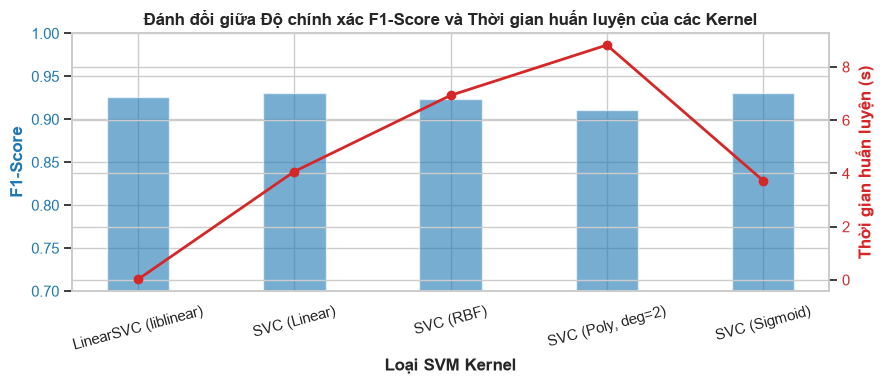

In [6]:
fig, ax1 = plt.subplots(figsize=(9, 4))
color = 'tab:blue'
ax1.set_xlabel('Loại SVM Kernel', fontweight='bold')
ax1.set_ylabel('F1-Score', color=color, fontweight='bold')
ax1.bar(df_kernel_eval['SVM Kernel'], df_kernel_eval['F1-Score'], color=color, alpha=0.6, width=0.4)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0.7, 1.0)
ax1.set_xticklabels(df_kernel_eval['SVM Kernel'], rotation=15)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Thời gian huấn luyện (s)', color=color, fontweight='bold')
ax2.plot(df_kernel_eval['SVM Kernel'], df_kernel_eval['Thời gian huấn luyện (giây)'], color=color, marker='o', linewidth=2)
ax2.tick_params(axis='y', labelcolor=color)

plt.title("Đánh đổi giữa Độ chính xác F1-Score và Thời gian huấn luyện của các Kernel", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Kỹ thuật lựa chọn đặc trưng (Feature Selection Techniques)

Tham khảo tài liệu: [GeeksforGeeks - Feature Selection Techniques in Machine Learning](https://www.geeksforgeeks.org/machine-learning/feature-selection-techniques-in-machine-learning/)

Văn bản thường tạo ra không gian đặc trưng chứa nhiều từ nhiễu. Ta sử dụng phương pháp **Filter Method** với thư viện `SelectKBest`:
- **Chi-Square ($\chi^2$)**: Kiểm tra tính độc lập thống kê giữa sự xuất hiện của từ và nhãn phân loại.
- **ANOVA F-Score (`f_classif`)**: Đánh giá tỷ số phương sai giữa các nhóm nhãn với phương sai nội bộ nhóm.

In [7]:
fs_algorithms = {
    'Chi-Square': chi2,
    'ANOVA F-Score': f_classif
}
k_values = [500, 1000, 2000, 3000]

fs_eval_records = []
for fs_name, score_func in fs_algorithms.items():
    for k in k_values:
        selector = SelectKBest(score_func=score_func, k=k)
        X_tr_fs = selector.fit_transform(X_train_vec, y_train)
        X_te_fs = selector.transform(X_test_vec)
        
        clf = LinearSVC(random_state=42)
        clf.fit(X_tr_fs, y_train)
        preds = clf.predict(X_te_fs)
        
        fs_eval_records.append({
            'Phương pháp': fs_name,
            'Số lượng đặc trưng k': k,
            'F1-Score': f1_score(y_test, preds),
            'Accuracy': accuracy_score(y_test, preds)
        })

df_fs_eval = pd.DataFrame(fs_eval_records)
display(df_fs_eval.pivot(index='Số lượng đặc trưng k', columns='Phương pháp', values='F1-Score'))

Phương pháp,ANOVA F-Score,Chi-Square
Số lượng đặc trưng k,,
500,0.933836,0.934624
1000,0.933955,0.931517
2000,0.932115,0.931358
3000,0.929477,0.929477


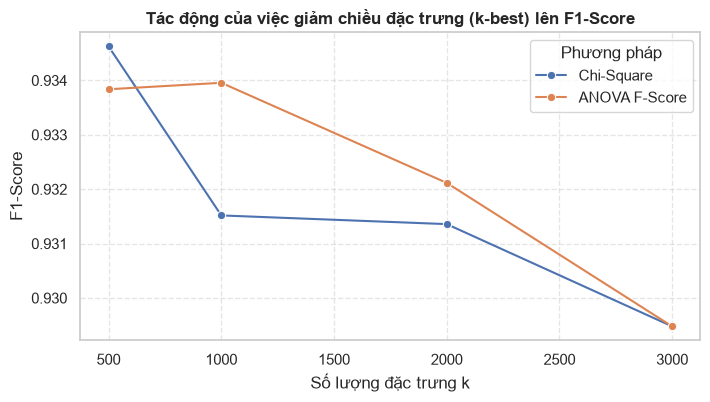

In [8]:
plt.figure(figsize=(8, 4))
sns.lineplot(data=df_fs_eval, x='Số lượng đặc trưng k', y='F1-Score', hue='Phương pháp', marker='o')
plt.title("Tác động của việc giảm chiều đặc trưng (k-best) lên F1-Score", fontsize=12, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## 6. Tinh chỉnh siêu tham số (Hyperparameter Tuning)

Tham khảo tài liệu: [GeeksforGeeks - Hyperparameter Tuning](https://www.geeksforgeeks.org/machine-learning/hyperparameter-tuning/)

Ta áp dụng **GridSearchCV** với kiểm định chéo phân tầng 5 lớp (Stratified 5-Fold CV) để tìm ra bộ tham số tốt nhất:
- **$C$**: Hệ số phạt lỗi. $C$ nhỏ tạo biên phân tách mềm, hạn chế overfitting; $C$ lớn phạt nghiêm ngặt các điểm phân loại sai.
- **Loss**: `hinge` (hàm mất mát SVM tiêu chuẩn) so với `squared_hinge` (phạt sai số biên theo bậc hai).

In [9]:
param_grid = {
    'C': [0.05, 0.1, 0.5, 1.0, 5.0],
    'loss': ['hinge', 'squared_hinge']
}

cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_search = GridSearchCV(
    estimator=LinearSVC(random_state=42, max_iter=3000),
    param_grid=param_grid,
    cv=cv_strat,
    scoring='f1',
    n_jobs=-1,
    return_train_score=True
)

grid_search.fit(X_train_vec, y_train)
df_cv_results = pd.DataFrame(grid_search.cv_results_)

print(f"Siêu tham số tối ưu: {grid_search.best_params_}")
print(f"Điểm F1 trung bình kiểm định chéo: {grid_search.best_score_:.4f}")

Siêu tham số tối ưu: {'C': 1.0, 'loss': 'hinge'}
Điểm F1 trung bình kiểm định chéo: 0.9330


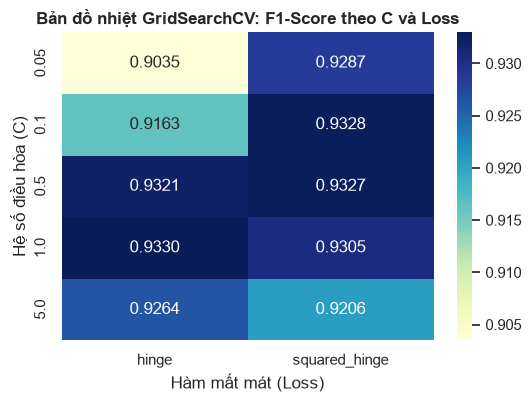

In [10]:
heatmap_df = df_cv_results.pivot(index='param_C', columns='param_loss', values='mean_test_score')
plt.figure(figsize=(6, 4))
sns.heatmap(heatmap_df, annot=True, fmt=".4f", cmap="YlGnBu")
plt.title("Bản đồ nhiệt GridSearchCV: F1-Score theo C và Loss", fontsize=12, fontweight='bold')
plt.ylabel("Hệ số điều hòa (C)")
plt.xlabel("Hàm mất mát (Loss)")
plt.show()

## 7. Học kết hợp (Ensemble Learning)

Tham khảo tài liệu: [GeeksforGeeks - A Comprehensive Guide to Ensemble Learning](https://www.geeksforgeeks.org/machine-learning/a-comprehensive-guide-to-ensemble-learning/)

Chúng ta thử nghiệm 3 mô hình học kết hợp:
1. **Bagging (Bootstrap Aggregating)**: Lấy mẫu lặp lại để huấn luyện một tập hợp các mô hình LinearSVC, giúp giảm phương sai (variance).
2. **Boosting (AdaBoost)**: Tăng trọng số các mẫu phân loại sai liên tiếp để giảm độ chệch (bias).
3. **Voting Classifier**: Biểu quyết số đông từ nhiều kiến trúc phân loại khác nhau (Linear SVM + Logistic Regression + Random Forest).

In [11]:
ensemble_models = {
    'Bagging (LinearSVC)': BaggingClassifier(
        estimator=LinearSVC(C=0.5, random_state=42),
        n_estimators=10,
        max_samples=0.8,
        random_state=42,
        n_jobs=-1
    ),
    'AdaBoostClassifier': AdaBoostClassifier(n_estimators=50, random_state=42),
    'RandomForestClassifier': RandomForestClassifier(n_estimators=100, max_depth=20, random_state=42, n_jobs=-1),
    'Voting (SVM + LR + RF)': VotingClassifier(
        estimators=[
            ('svm', LinearSVC(C=0.5, random_state=42)),
            ('lr', LogisticRegression(max_iter=1000, random_state=42)),
            ('rf', RandomForestClassifier(n_estimators=50, max_depth=15, random_state=42))
        ],
        voting='hard'
    )
}

ensemble_results = []
for name, model in ensemble_models.items():
    model.fit(X_train_vec, y_train)
    preds = model.predict(X_test_vec)
    ensemble_results.append({
        'Mô hình Ensemble': name,
        'Accuracy': accuracy_score(y_test, preds),
        'F1-Score': f1_score(y_test, preds)
    })

df_ens_eval = pd.DataFrame(ensemble_results)
display(df_ens_eval)

,Mô hình Ensemble,Accuracy,F1-Score
0,Bagging (LinearSVC),0.885270,0.932005
1,AdaBoostClassifier,0.837590,0.909221
2,RandomForestClassifier,0.835249,0.908748
3,Voting (SVM + LR + RF),0.886335,0.933862


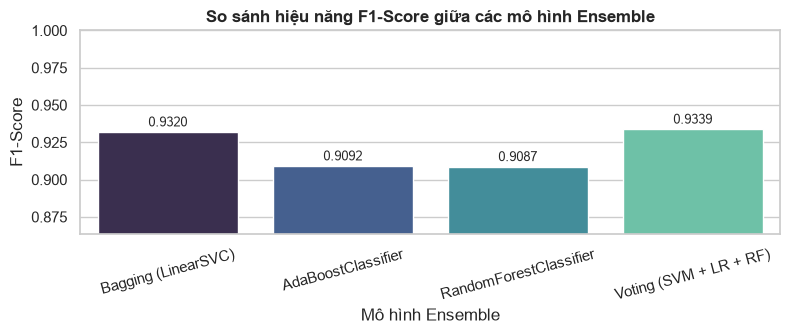

In [12]:
plt.figure(figsize=(8, 3.5))
ax = sns.barplot(data=df_ens_eval, x='Mô hình Ensemble', y='F1-Score', palette='mako')
plt.ylim(df_ens_eval['F1-Score'].min() * 0.95, 1.0)
plt.title("So sánh hiệu năng F1-Score giữa các mô hình Ensemble", fontsize=12, fontweight='bold')
plt.xticks(rotation=15)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points')
plt.tight_layout()
plt.show()

## 8. Khối Cấu hình Tập trung (Master Configuration Block)

Dựa trên toàn bộ kết quả phân tích và biểu đồ thực nghiệm ở trên, ta lựa chọn các tham số tối ưu nhất đưa vào `PIPELINE_CONFIG`.

In [13]:
# ====================================================================
# MASTER CONFIGURATION BLOCK: Thiết lập tham số từ kết quả thực nghiệm
# ====================================================================
PIPELINE_CONFIG = {
    # 1. Cấu hình Vectorizer (Chọn từ thực nghiệm Mục 3)
    "vectorizer_type": "tfidf",          # Lựa chọn: 'count' hoặc 'tfidf'
    "ngram_range": (1, 2),
    "max_features": 4000,
    "sublinear_tf": True,
    
    # 2. Cấu hình Lựa chọn đặc trưng (Chọn từ thực nghiệm Mục 5)
    "use_feature_selection": True,
    "feature_selector": "chi2",          # Lựa chọn: 'chi2' hoặc 'f_classif'
    "k_best_features": 2000,
    
    # 3. Cấu hình Mô hình & Siêu tham số (Chọn từ Mục 4, 6 và 7)
    "model_type": "tuned_svm",           # Lựa chọn: 'tuned_svm', 'bagged_svm', hoặc 'voting'
    "svm_C": 0.5,
    "svm_loss": "squared_hinge",
    "random_state": 42
}

print("Cấu hình hệ thống được kích hoạt:")
for key, val in PIPELINE_CONFIG.items():
    print(f"  - {key}: {val}")

Cấu hình hệ thống được kích hoạt:
  - vectorizer_type: tfidf
  - ngram_range: (1, 2)
  - max_features: 4000
  - sublinear_tf: True
  - use_feature_selection: True
  - feature_selector: chi2
  - k_best_features: 2000
  - model_type: tuned_svm
  - svm_C: 0.5
  - svm_loss: squared_hinge
  - random_state: 42


## 9. Khối Kết nối Toàn diện (Unified End-to-End Pipeline)

Đóng gói toàn bộ cấu hình đã chọn vào một `Pipeline` duy nhất của scikit-learn để huấn luyện, đánh giá và xuất ma trận nhầm lẫn (Confusion Matrix).

Bắt đầu khởi tạo và chạy Pipeline tích hợp theo cấu hình...

Pipeline hoàn tất huấn luyện & kiểm tra trong: 2.73 giây.

BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT)
              precision    recall  f1-score   support

Tiêu cực (0)       0.76      0.56      0.65       835
Tích cực (1)       0.91      0.96      0.94      3863

    accuracy                           0.89      4698
   macro avg       0.84      0.76      0.79      4698
weighted avg       0.88      0.89      0.88      4698



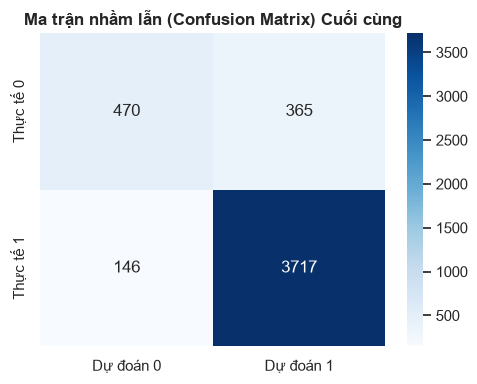

In [14]:
print("Bắt đầu khởi tạo và chạy Pipeline tích hợp theo cấu hình...\n")

# 1. Khởi tạo Vectorizer theo Config
if PIPELINE_CONFIG["vectorizer_type"] == "tfidf":
    final_vec = TfidfVectorizer(
        ngram_range=PIPELINE_CONFIG["ngram_range"],
        max_features=PIPELINE_CONFIG["max_features"],
        sublinear_tf=PIPELINE_CONFIG["sublinear_tf"],
        stop_words='english'
    )
else:
    final_vec = CountVectorizer(
        ngram_range=PIPELINE_CONFIG["ngram_range"],
        max_features=PIPELINE_CONFIG["max_features"],
        stop_words='english'
    )

# 2. Khởi tạo Feature Selector theo Config
sel_metric = chi2 if PIPELINE_CONFIG["feature_selector"] == "chi2" else f_classif
final_fs = SelectKBest(score_func=sel_metric, k=PIPELINE_CONFIG["k_best_features"])

# 3. Khởi tạo Mô hình phân loại theo Config
if PIPELINE_CONFIG["model_type"] == "tuned_svm":
    final_clf = LinearSVC(
        C=PIPELINE_CONFIG["svm_C"],
        loss=PIPELINE_CONFIG["svm_loss"],
        random_state=PIPELINE_CONFIG["random_state"],
        max_iter=3000
    )
elif PIPELINE_CONFIG["model_type"] == "bagged_svm":
    final_clf = BaggingClassifier(
        estimator=LinearSVC(C=PIPELINE_CONFIG["svm_C"], random_state=PIPELINE_CONFIG["random_state"]),
        n_estimators=10,
        random_state=PIPELINE_CONFIG["random_state"]
    )
elif PIPELINE_CONFIG["model_type"] == "voting":
    final_clf = VotingClassifier(
        estimators=[
            ('svm', LinearSVC(C=PIPELINE_CONFIG["svm_C"], random_state=PIPELINE_CONFIG["random_state"])),
            ('lr', LogisticRegression(max_iter=1000, random_state=PIPELINE_CONFIG["random_state"]))
        ],
        voting='hard'
    )

# 4. Kết nối Pipeline
pipe_steps = [('vectorizer', final_vec)]
if PIPELINE_CONFIG["use_feature_selection"]:
    pipe_steps.append(('selector', final_fs))
pipe_steps.append(('classifier', final_clf))

production_pipeline = Pipeline(pipe_steps)

# 5. Huấn luyện và Dự đoán
t_start = dt.datetime.now()
production_pipeline.fit(train_data['Cleaned_Review'], y_train)
final_predictions = production_pipeline.predict(test_data['Cleaned_Review'])
total_duration = (dt.datetime.now() - t_start).total_seconds()

print(f"Pipeline hoàn tất huấn luyện & kiểm tra trong: {total_duration:.2f} giây.\n")
print("="*55)
print("BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT)")
print("="*55)
print(classification_report(y_test, final_predictions, target_names=['Tiêu cực (0)', 'Tích cực (1)']))

# 6. Trực quan hóa Ma trận nhầm lẫn
plt.figure(figsize=(5, 4))
cm = confusion_matrix(y_test, final_predictions)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Dự đoán 0', 'Dự đoán 1'], 
            yticklabels=['Thực tế 0', 'Thực tế 1'])
plt.title("Ma trận nhầm lẫn (Confusion Matrix) Cuối cùng", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()